### Lab 8 Meeting 2 ###

In [ ]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, state_fidelity
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_aer.noise import ReadoutError
from qiskit_aer.noise import depolarizing_error
from qiskit.visualization import plot_bloch_multivector, plot_state_qsphere, plot_histogram
import matplotlib.pyplot as plt
import numpy as np

sim = AerSimulator()

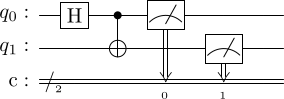

In [49]:
# Ideal Circuit

qc = QuantumCircuit(2,2)
qc.h(0)
qc.cx(0,1)
qc.measure([0,1],[0,1])
qc.draw("latex")


### s = {1,3,5}, depolarizing error probability = .05

In [8]:
# Noise
#   - Gate noise (depolarizing error on CX gates)
#   - Readout noise (Classical bit-flip during measurement)

noise_model = NoiseModel()

# Gate noise: Depolarizing gate error with 5% error rate on every two-qubit CX gate
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.05, 2), ['cx'])

# Readout error (e.g., 10-20% misread per qubit)
p0given1 = 0.15 # misread 1 as 0
p1given0 = 0.15 # misread 0 as 1

readout = ReadoutError([[1-p1given0, p1given0],[p0given1, 1-p0given1]])

for qubit in range(2):
    noise_model.add_readout_error(readout, [qubit])

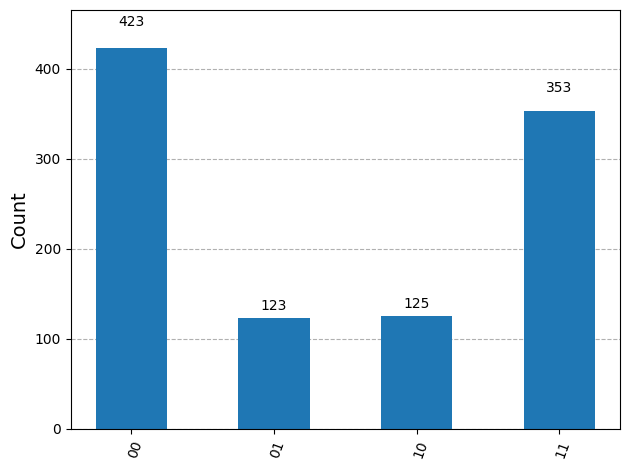

In [9]:
# 1. Initialize the simulator with the noise model
backend = AerSimulator(noise_model=noise_model)

# 2. Transpile and Run (Replaces execute)
transpiled_qc = transpile(qc, backend)
job = backend.run(transpiled_qc, shots=1024)

# 3. Get results and plot
noisy_counts = job.result().get_counts()
plot_histogram(noisy_counts)

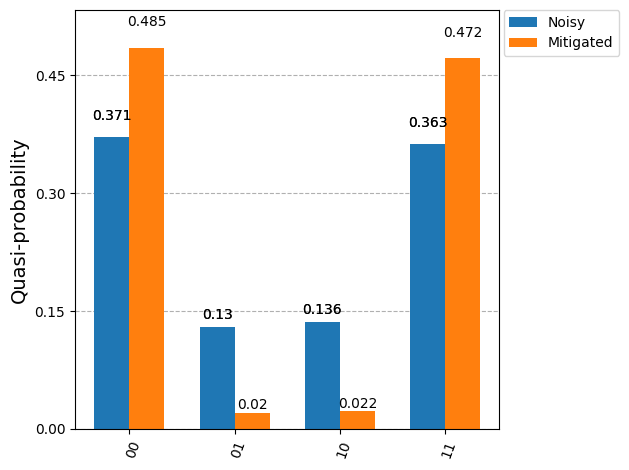

In [12]:
from qiskit_experiments.library import CorrelatedReadoutError
# 1. Calibrate on the noisy backend
exp = CorrelatedReadoutError(physical_qubits=[0,1])
exp_data = exp.run(backend = backend).block_for_results()

# 2. Extract Mitigator
# meas_fitter - exp_data.analysis_results("Correlated Readout Mitigator").value
# Get all results as a pandas DataFrame (avoids the warning)
df = exp_data.analysis_results(dataframe = True)
# Filter for the mitigator and extract its value
meas_fitter = df.loc[df["name"] == "Correlated Readout Mitigator", "value"].iloc[0]

# 3. Run the Bell Circuit
qc_t = transpile(qc, backend)
noisy_counts = backend.run(qc_t, shots=1024).result().get_counts()

# 4. Mitigate
mitigated_quasi = meas_fitter.quasi_probabilities(noisy_counts)
mitigated_dict = mitigated_quasi.binary_probabilities(num_bits = 2)

# 5. Compare
plot_histogram([noisy_counts, mitigated_dict], legend=["Noisy", "Mitigated"])

In [13]:
def fold_circuit(qc, scale_factor):
    if scale_factor % 2 == 0:
        raise ValueError("Scale factor must be odd.")

    # 1. Separate Unitary gates from Measurements
    unitary_qc = qc.copy()
    unitary_qc.remove_final_measurements() # Built-in Qiskit method

    # 2. Perform the Folding (U -> U U* U)
    folded = unitary_qc.copy()
    num_pairs = (scale_factor - 1) // 2

    u_inv = unitary_qc.inverse()
    for _ in range(num_pairs):
        folded.compose(u_inv, inplace=True)
        folded.compose(unitary_qc, inplace=True)

    # 3. Re-add measurements based on the original circuit's layout
    folded.measure_all() # Adds new bits and measures everything

    return folded



In [18]:
def expectation_zz(counts):
    total_shots = sum(counts.values())
    exp = 0

    for bitstring, count in counts.items():
        # In Qiskit, bitstring '01' means qubit 1 is 0 and qubit 0 is 1.
        # For ZZ, we parity-check the bits.
        # Even number of 1s -> +1, Odd number of 1s -> -1
        parity = bitstring.count("1") % 2 # Check if sum of bits is odd/even
        z_val = 1 if parity == 0 else -1 # Even -> +1, Odd -> -1

        exp += z_val * count # Accumulate weighted values
    return exp / total_shots

In [19]:
# Expectation Value for the Bell State
expectations = []
scales = [1,3,5]

for s in scales:
    # 1. Fold the circuit  (now works even with measure)
    folded_qc = fold_circuit(qc, s)

    # 2. Transpile with no optimization
    t_folded_qc = transpile(folded_qc, backend, optimization_level=0)

    # 3. Run
    job = backend.run(t_folded_qc, shots=1024)
    res = job.result()
    counts = res.get_counts()

    # 4. Compute expectation
    expectations.append(expectation_zz(counts))

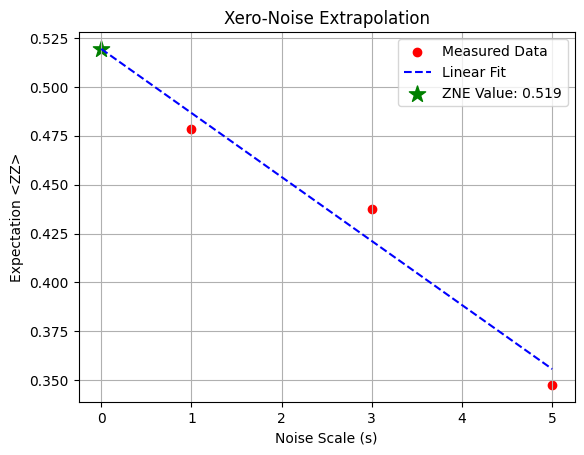

In [25]:
# 1. Fit the data
coeffs = np.polyfit(scales, expectations, deg=1)
zne_value = np.polyval(coeffs, 0)

# 2. Create the fit line (extending from 0 to your max scale)
x_fit = np.linspace(0,max(scales), 100)
y_fit = np.polyval(coeffs, x_fit)

# 3. Plotting
plt.scatter(scales, expectations, color='red', label='Measured Data')
plt.plot(x_fit, y_fit, '--', color='blue', label='Linear Fit')
plt.scatter(0, zne_value, color='green', marker='*', s=150, label=f'ZNE Value: {zne_value:.3f}')

plt.xlabel('Noise Scale (s)')
plt.ylabel('Expectation <ZZ>')
plt.title('Xero-Noise Extrapolation')
plt.legend()
plt . grid (True)
plt.show()

In [24]:
print("Raw expectation:", expectations[0])
print("ZNE extrapolated:", zne_value)

Raw expectation: 0.478515625
ZNE extrapolated: 0.519368489583333


### s = {1,3,5}, depolarizing error probability = .10

In [72]:
# Noise
#   - Gate noise (depolarizing error on CX gates)
#   - Readout noise (Classical bit-flip during measurement)

noise_model = NoiseModel()

# Gate noise: Depolarizing gate error with 5% error rate on every two-qubit CX gate
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.1, 2), ['cx'])

# Readout error (e.g., 10-20% misread per qubit)
p0given1 = 0.15 # misread 1 as 0
p1given0 = 0.15 # misread 0 as 1

readout = ReadoutError([[1-p1given0, p1given0],[p0given1, 1-p0given1]])

for qubit in range(2):
    noise_model.add_readout_error(readout, [qubit])

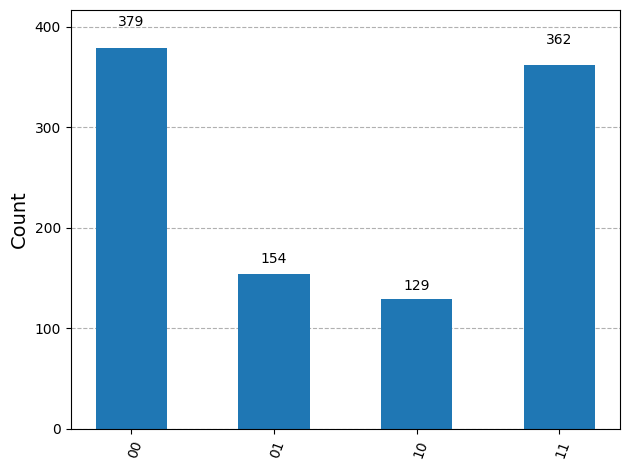

In [73]:
# 1. Initialize the simulator with the noise model
backend = AerSimulator(noise_model=noise_model)

# 2. Transpile and Run (Replaces execute)
transpiled_qc = transpile(qc, backend)
job = backend.run(transpiled_qc, shots=1024)

# 3. Get results and plot
noisy_counts = job.result().get_counts()
plot_histogram(noisy_counts)

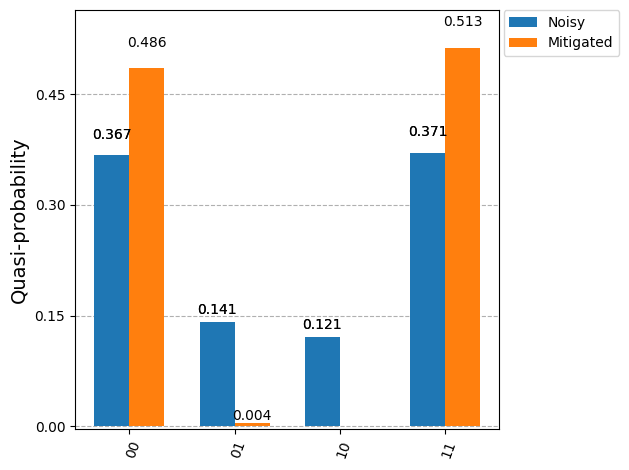

In [74]:
from qiskit_experiments.library import CorrelatedReadoutError
# 1. Calibrate on the noisy backend
exp = CorrelatedReadoutError(physical_qubits=[0,1])
exp_data = exp.run(backend = backend).block_for_results()

# 2. Extract Mitigator
# meas_fitter - exp_data.analysis_results("Correlated Readout Mitigator").value
# Get all results as a pandas DataFrame (avoids the warning)
df = exp_data.analysis_results(dataframe = True)
# Filter for the mitigator and extract its value
meas_fitter = df.loc[df["name"] == "Correlated Readout Mitigator", "value"].iloc[0]

# 3. Run the Bell Circuit
qc_t = transpile(qc, backend)
noisy_counts = backend.run(qc_t, shots=1024).result().get_counts()

# 4. Mitigate
mitigated_quasi = meas_fitter.quasi_probabilities(noisy_counts)
mitigated_dict = mitigated_quasi.binary_probabilities(num_bits = 2)

# 5. Compare
plot_histogram([noisy_counts, mitigated_dict], legend=["Noisy", "Mitigated"])

In [75]:
# Expectation Value for the Bell State
expectations = []
scales = [1,3,5]

for s in scales:
    # 1. Fold the circuit  (now works even with measure)
    folded_qc = fold_circuit(qc, s)

    # 2. Transpile with no optimization
    t_folded_qc = transpile(folded_qc, backend, optimization_level=0)

    # 3. Run
    job = backend.run(t_folded_qc, shots=1024)
    res = job.result()
    counts = res.get_counts()

    # 4. Compute expectation
    expectations.append(expectation_zz(counts))

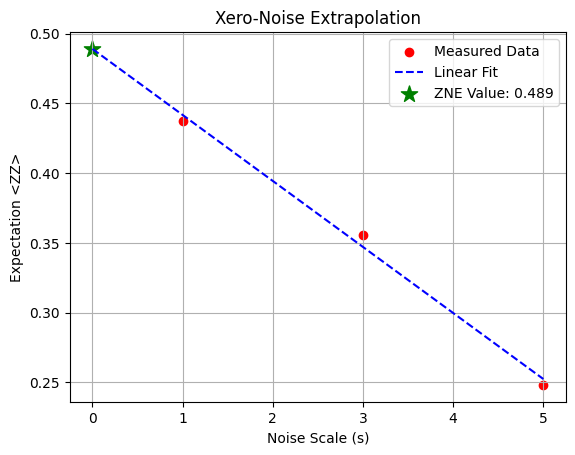

In [76]:
# 1. Fit the data
coeffs = np.polyfit(scales, expectations, deg=1)
zne_value = np.polyval(coeffs, 0)

# 2. Create the fit line (extending from 0 to your max scale)
x_fit = np.linspace(0,max(scales), 100)
y_fit = np.polyval(coeffs, x_fit)

# 3. Plotting
plt.scatter(scales, expectations, color='red', label='Measured Data')
plt.plot(x_fit, y_fit, '--', color='blue', label='Linear Fit')
plt.scatter(0, zne_value, color='green', marker='*', s=150, label=f'ZNE Value: {zne_value:.3f}')

plt.xlabel('Noise Scale (s)')
plt.ylabel('Expectation <ZZ>')
plt.title('Xero-Noise Extrapolation')
plt.legend()
plt . grid (True)
plt.show()

In [77]:
print("Raw expectation:", expectations[0])
print("ZNE extrapolated:", zne_value)

Raw expectation: 0.4375
ZNE extrapolated: 0.4890950520833331


### s = {1,3,5}, depolarizing error probability = .2

In [144]:
# Noise
#   - Gate noise (depolarizing error on CX gates)
#   - Readout noise (Classical bit-flip during measurement)

noise_model = NoiseModel()

# Gate noise: Depolarizing gate error with 5% error rate on every two-qubit CX gate
noise_model.add_all_qubit_quantum_error(depolarizing_error(1, 2), ['cx'])

# Readout error (e.g., 10-20% misread per qubit)
p0given1 = 0.15 # misread 1 as 0
p1given0 = 0.15 # misread 0 as 1

readout = ReadoutError([[1-p1given0, p1given0],[p0given1, 1-p0given1]])

for qubit in range(2):
    noise_model.add_readout_error(readout, [qubit])

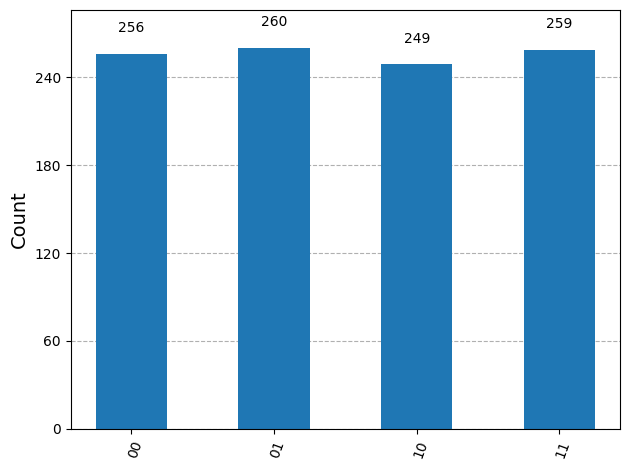

In [145]:
# 1. Initialize the simulator with the noise model
backend = AerSimulator(noise_model=noise_model)

# 2. Transpile and Run (Replaces execute)
transpiled_qc = transpile(qc, backend)
job = backend.run(transpiled_qc, shots=1024)

# 3. Get results and plot
noisy_counts = job.result().get_counts()
plot_histogram(noisy_counts)

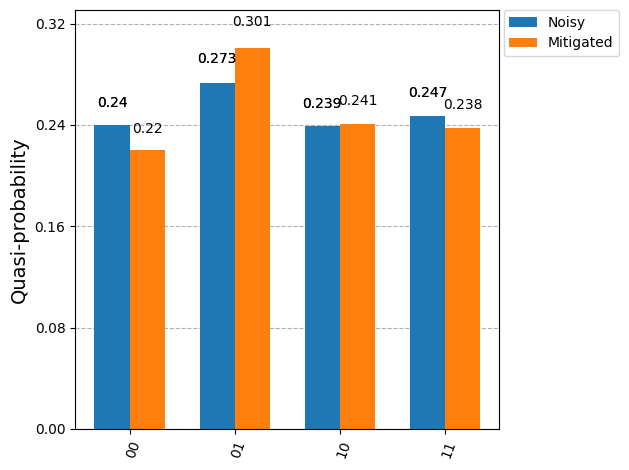

In [146]:
from qiskit_experiments.library import CorrelatedReadoutError
# 1. Calibrate on the noisy backend
exp = CorrelatedReadoutError(physical_qubits=[0,1])
exp_data = exp.run(backend = backend).block_for_results()

# 2. Extract Mitigator
# meas_fitter - exp_data.analysis_results("Correlated Readout Mitigator").value
# Get all results as a pandas DataFrame (avoids the warning)
df = exp_data.analysis_results(dataframe = True)
# Filter for the mitigator and extract its value
meas_fitter = df.loc[df["name"] == "Correlated Readout Mitigator", "value"].iloc[0]

# 3. Run the Bell Circuit
qc_t = transpile(qc, backend)
noisy_counts = backend.run(qc_t, shots=1024).result().get_counts()

# 4. Mitigate
mitigated_quasi = meas_fitter.quasi_probabilities(noisy_counts)
mitigated_dict = mitigated_quasi.binary_probabilities(num_bits = 2)

# 5. Compare
plot_histogram([noisy_counts, mitigated_dict], legend=["Noisy", "Mitigated"])

In [147]:
# Expectation Value for the Bell State
expectations = []
scales = [1,3,5]

for s in scales:
    # 1. Fold the circuit  (now works even with measure)
    folded_qc = fold_circuit(qc, s)

    # 2. Transpile with no optimization
    t_folded_qc = transpile(folded_qc, backend, optimization_level=0)

    # 3. Run
    job = backend.run(t_folded_qc, shots=1024)
    res = job.result()
    counts = res.get_counts()

    # 4. Compute expectation
    expectations.append(expectation_zz(counts))

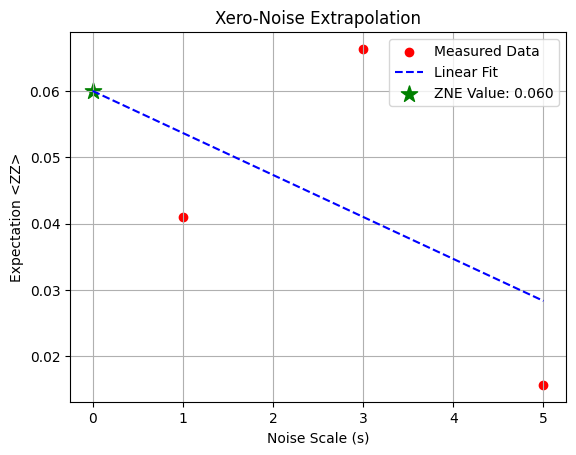

In [148]:
# 1. Fit the data
coeffs = np.polyfit(scales, expectations, deg=1)
zne_value = np.polyval(coeffs, 0)

# 2. Create the fit line (extending from 0 to your max scale)
x_fit = np.linspace(0,max(scales), 100)
y_fit = np.polyval(coeffs, x_fit)

# 3. Plotting
plt.scatter(scales, expectations, color='red', label='Measured Data')
plt.plot(x_fit, y_fit, '--', color='blue', label='Linear Fit')
plt.scatter(0, zne_value, color='green', marker='*', s=150, label=f'ZNE Value: {zne_value:.3f}')

plt.xlabel('Noise Scale (s)')
plt.ylabel('Expectation <ZZ>')
plt.title('Xero-Noise Extrapolation')
plt.legend()
plt . grid (True)
plt.show()

In [149]:
print("Raw expectation:", expectations[0])
print("ZNE extrapolated:", zne_value)

Raw expectation: 0.041015625
ZNE extrapolated: 0.060058593749999965


### s = {1,3,5,7}, depolarizing error probability = .05

In [38]:
# Noise
#   - Gate noise (depolarizing error on CX gates)
#   - Readout noise (Classical bit-flip during measurement)

noise_model = NoiseModel()

# Gate noise: Depolarizing gate error with 5% error rate on every two-qubit CX gate
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.05, 2), ['cx'])

# Readout error (e.g., 10-20% misread per qubit)
p0given1 = 0.15 # misread 1 as 0
p1given0 = 0.15 # misread 0 as 1

readout = ReadoutError([[1-p1given0, p1given0],[p0given1, 1-p0given1]])

for qubit in range(2):
    noise_model.add_readout_error(readout, [qubit])

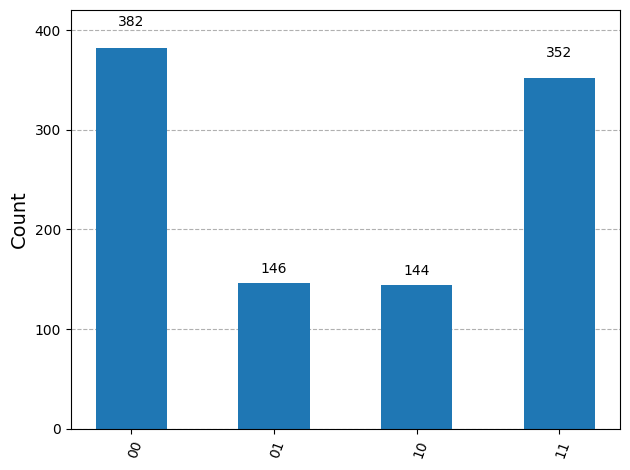

In [39]:
# 1. Initialize the simulator with the noise model
backend = AerSimulator(noise_model=noise_model)

# 2. Transpile and Run (Replaces execute)
transpiled_qc = transpile(qc, backend)
job = backend.run(transpiled_qc, shots=1024)

# 3. Get results and plot
noisy_counts = job.result().get_counts()
plot_histogram(noisy_counts)

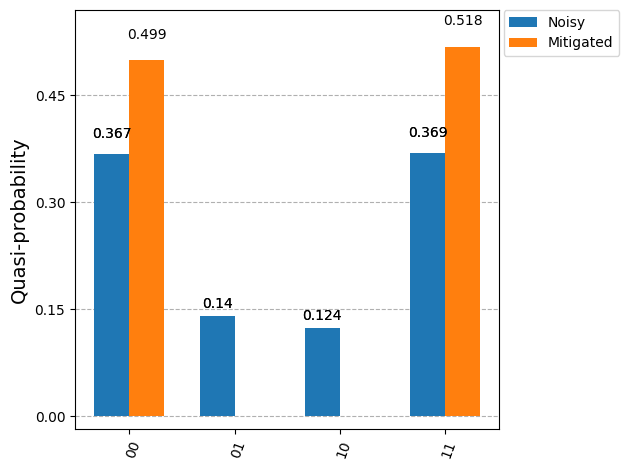

In [40]:
from qiskit_experiments.library import CorrelatedReadoutError
# 1. Calibrate on the noisy backend
exp = CorrelatedReadoutError(physical_qubits=[0,1])
exp_data = exp.run(backend = backend).block_for_results()

# 2. Extract Mitigator
# meas_fitter - exp_data.analysis_results("Correlated Readout Mitigator").value
# Get all results as a pandas DataFrame (avoids the warning)
df = exp_data.analysis_results(dataframe = True)
# Filter for the mitigator and extract its value
meas_fitter = df.loc[df["name"] == "Correlated Readout Mitigator", "value"].iloc[0]

# 3. Run the Bell Circuit
qc_t = transpile(qc, backend)
noisy_counts = backend.run(qc_t, shots=1024).result().get_counts()

# 4. Mitigate
mitigated_quasi = meas_fitter.quasi_probabilities(noisy_counts)
mitigated_dict = mitigated_quasi.binary_probabilities(num_bits = 2)

# 5. Compare
plot_histogram([noisy_counts, mitigated_dict], legend=["Noisy", "Mitigated"])

In [41]:
# Expectation Value for the Bell State
expectations = []
scales = [1,3,5,7]

for s in scales:
    # 1. Fold the circuit  (now works even with measure)
    folded_qc = fold_circuit(qc, s)

    # 2. Transpile with no optimization
    t_folded_qc = transpile(folded_qc, backend, optimization_level=0)

    # 3. Run
    job = backend.run(t_folded_qc, shots=1024)
    res = job.result()
    counts = res.get_counts()

    # 4. Compute expectation
    expectations.append(expectation_zz(counts))

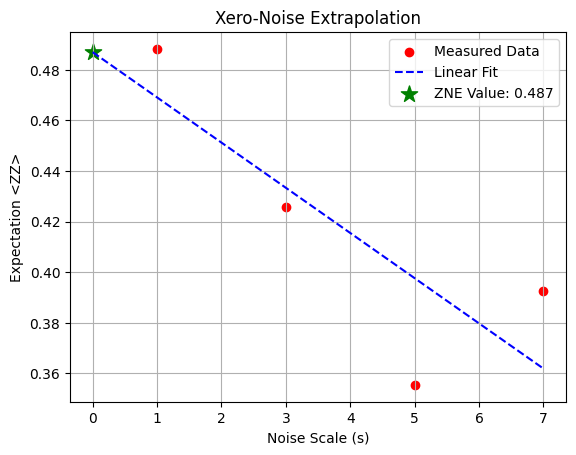

In [42]:
# 1. Fit the data
coeffs = np.polyfit(scales, expectations, deg=1)
zne_value = np.polyval(coeffs, 0)

# 2. Create the fit line (extending from 0 to your max scale)
x_fit = np.linspace(0,max(scales), 100)
y_fit = np.polyval(coeffs, x_fit)

# 3. Plotting
plt.scatter(scales, expectations, color='red', label='Measured Data')
plt.plot(x_fit, y_fit, '--', color='blue', label='Linear Fit')
plt.scatter(0, zne_value, color='green', marker='*', s=150, label=f'ZNE Value: {zne_value:.3f}')

plt.xlabel('Noise Scale (s)')
plt.ylabel('Expectation <ZZ>')
plt.title('Xero-Noise Extrapolation')
plt.legend()
plt . grid (True)
plt.show()

In [43]:
print("Raw expectation:", expectations[0])
print("ZNE extrapolated:", zne_value)

Raw expectation: 0.48828125
ZNE extrapolated: 0.48701171875


### s = {1,3,5}, depolarizing error probability = .05, Less shots (128)

In [163]:
# Noise
#   - Gate noise (depolarizing error on CX gates)
#   - Readout noise (Classical bit-flip during measurement)

noise_model = NoiseModel()

# Gate noise: Depolarizing gate error with 5% error rate on every two-qubit CX gate
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.05, 2), ['cx'])

# Readout error (e.g., 10-20% misread per qubit)
p0given1 = 0.15 # misread 1 as 0
p1given0 = 0.15 # misread 0 as 1

readout = ReadoutError([[1-p1given0, p1given0],[p0given1, 1-p0given1]])

for qubit in range(2):
    noise_model.add_readout_error(readout, [qubit])

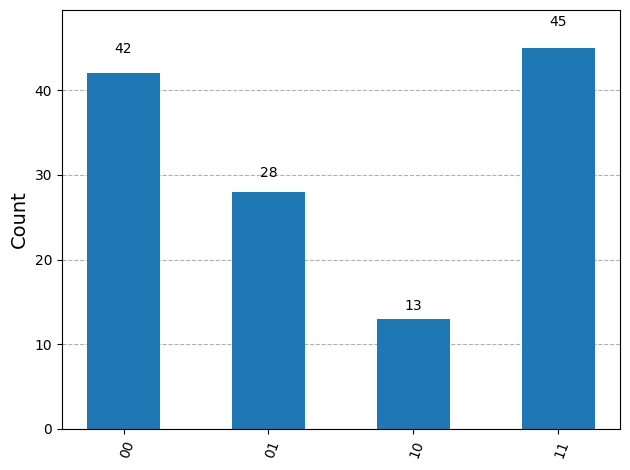

In [164]:
# 1. Initialize the simulator with the noise model
backend = AerSimulator(noise_model=noise_model)

# 2. Transpile and Run (Replaces execute)
transpiled_qc = transpile(qc, backend)
job = backend.run(transpiled_qc, shots=128)

# 3. Get results and plot
noisy_counts = job.result().get_counts()
plot_histogram(noisy_counts)

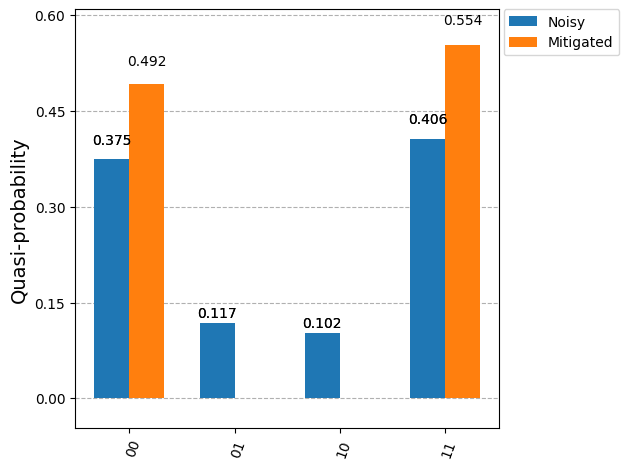

In [165]:
from qiskit_experiments.library import CorrelatedReadoutError
# 1. Calibrate on the noisy backend
exp = CorrelatedReadoutError(physical_qubits=[0,1])
exp_data = exp.run(backend = backend).block_for_results()

# 2. Extract Mitigator
# meas_fitter - exp_data.analysis_results("Correlated Readout Mitigator").value
# Get all results as a pandas DataFrame (avoids the warning)
df = exp_data.analysis_results(dataframe = True)
# Filter for the mitigator and extract its value
meas_fitter = df.loc[df["name"] == "Correlated Readout Mitigator", "value"].iloc[0]

# 3. Run the Bell Circuit
qc_t = transpile(qc, backend)
noisy_counts = backend.run(qc_t, shots=128).result().get_counts()

# 4. Mitigate
mitigated_quasi = meas_fitter.quasi_probabilities(noisy_counts)
mitigated_dict = mitigated_quasi.binary_probabilities(num_bits = 2)

# 5. Compare
plot_histogram([noisy_counts, mitigated_dict], legend=["Noisy", "Mitigated"])

In [166]:
# Expectation Value for the Bell State
expectations = []
scales = [1,3,5]

for s in scales:
    # 1. Fold the circuit  (now works even with measure)
    folded_qc = fold_circuit(qc, s)

    # 2. Transpile with no optimization
    t_folded_qc = transpile(folded_qc, backend, optimization_level=0)

    # 3. Run
    job = backend.run(t_folded_qc, shots=128)
    res = job.result()
    counts = res.get_counts()

    # 4. Compute expectation
    expectations.append(expectation_zz(counts))

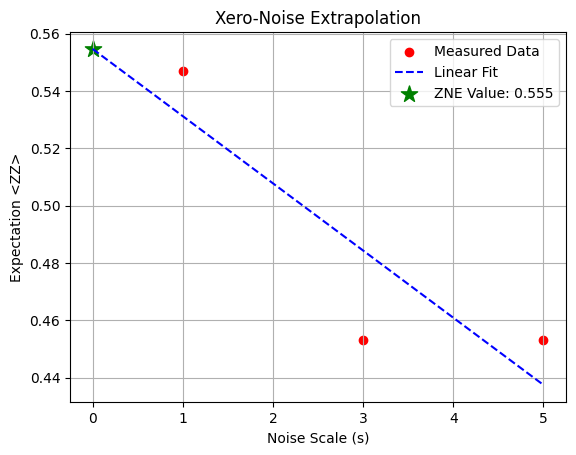

In [167]:
# 1. Fit the data
coeffs = np.polyfit(scales, expectations, deg=1)
zne_value = np.polyval(coeffs, 0)

# 2. Create the fit line (extending from 0 to your max scale)
x_fit = np.linspace(0,max(scales), 100)
y_fit = np.polyval(coeffs, x_fit)

# 3. Plotting
plt.scatter(scales, expectations, color='red', label='Measured Data')
plt.plot(x_fit, y_fit, '--', color='blue', label='Linear Fit')
plt.scatter(0, zne_value, color='green', marker='*', s=150, label=f'ZNE Value: {zne_value:.3f}')

plt.xlabel('Noise Scale (s)')
plt.ylabel('Expectation <ZZ>')
plt.title('Xero-Noise Extrapolation')
plt.legend()
plt . grid (True)
plt.show()

In [168]:
print("Raw expectation:", expectations[0])
print("ZNE extrapolated:", zne_value)

Raw expectation: 0.546875
ZNE extrapolated: 0.5546874999999998


### s = {1,3,5}, depolarizing error probability = .05
#### Testing stat fluxuations

In [ ]:
# Noise
#   - Gate noise (depolarizing error on CX gates)
#   - Readout noise (Classical bit-flip during measurement)



In [150]:
all_exp = []
all_zne = []
for _ in range(50):
    noise_model = NoiseModel()
    noise_model.add_all_qubit_quantum_error(depolarizing_error(0.05, 2), ['cx'])
    p0given1 = 0.15
    p1given0 = 0.15
    readout = ReadoutError([[1-p1given0, p1given0],[p0given1, 1-p0given1]])
    for qubit in range(2):
        noise_model.add_readout_error(readout, [qubit])
    backend = AerSimulator(noise_model=noise_model)
    transpiled_qc = transpile(qc, backend)
    job = backend.run(transpiled_qc, shots=1024)
    noisy_counts = job.result().get_counts()
    exp = CorrelatedReadoutError(physical_qubits=[0,1])
    exp_data = exp.run(backend = backend).block_for_results()
    df = exp_data.analysis_results(dataframe = True)
    meas_fitter = df.loc[df["name"] == "Correlated Readout Mitigator", "value"].iloc[0]
    qc_t = transpile(qc, backend)
    noisy_counts = backend.run(qc_t, shots=1024).result().get_counts()
    mitigated_quasi = meas_fitter.quasi_probabilities(noisy_counts)
    mitigated_dict = mitigated_quasi.binary_probabilities(num_bits = 2)
    expectations = []
    scales = [1,3,5,7]
    for s in scales:
        folded_qc = fold_circuit(qc, s)
        t_folded_qc = transpile(folded_qc, backend, optimization_level=0)
        job = backend.run(t_folded_qc, shots=1024)
        res = job.result()
        counts = res.get_counts()
        expectations.append(expectation_zz(counts))
    coeffs = np.polyfit(scales, expectations, deg=1)
    zne_value = np.polyval(coeffs, 0)
    all_exp.append(expectations[0])
    all_zne.append(zne_value)
all_exp.sort()
all_zne.sort()
print(f"Raw expectation: max({all_exp[0]}), min({all_exp[-1]})")
print(f"ZNE extrapolated: max({all_zne[0]}), min({all_zne[-1]})")
print(all_exp)
print(all_zne)

Raw expectation: max(0.400390625), min(0.521484375)
ZNE extrapolated: max(0.416796875), min(0.5380859374999998)
[0.400390625, 0.4140625, 0.41796875, 0.419921875, 0.421875, 0.4296875, 0.4296875, 0.431640625, 0.435546875, 0.4375, 0.4375, 0.439453125, 0.439453125, 0.443359375, 0.443359375, 0.44921875, 0.44921875, 0.451171875, 0.453125, 0.453125, 0.455078125, 0.458984375, 0.462890625, 0.462890625, 0.462890625, 0.462890625, 0.46484375, 0.46484375, 0.46484375, 0.466796875, 0.46875, 0.46875, 0.470703125, 0.470703125, 0.47265625, 0.47265625, 0.474609375, 0.478515625, 0.48046875, 0.482421875, 0.484375, 0.484375, 0.486328125, 0.486328125, 0.4921875, 0.498046875, 0.498046875, 0.501953125, 0.509765625, 0.521484375]
[np.float64(0.416796875), np.float64(0.4191406249999998), np.float64(0.4224609374999999), np.float64(0.43544921874999987), np.float64(0.44306640625000004), np.float64(0.44599609375000004), np.float64(0.4478515625), np.float64(0.44794921875000016), np.float64(0.45458984375000006), np.flo

In [ ]:
# Expectation Value for the Bell State
expectations = []
scales = [1,3,5]

for s in scales:
    # 1. Fold the circuit  (now works even with measure)
    folded_qc = fold_circuit(qc, s)

    # 2. Transpile with no optimization
    t_folded_qc = transpile(folded_qc, backend, optimization_level=0)

    # 3. Run
    job = backend.run(t_folded_qc, shots=1024)
    res = job.result()
    counts = res.get_counts()

    # 4. Compute expectation
    expectations.append(expectation_zz(counts))
coeffs = np.polyfit(scales, expectations, deg=1)
zne_value = np.polyval(coeffs, 0)
print("Raw expectation:", expectations[0])
print("ZNE extrapolated:", zne_value)

Raw expectation: 0.466796875
ZNE extrapolated: 0.5047200520833334
